# 05 — Uplift Modeling: Determining Who to Target
### SmartTel Retention Intelligence — (Future Work / Experimental Extension)

**Input:** `telco_features_scored_latest.parquet` (produced by `03_classification_benchmarking.ipynb`)

>  The core system (Modules 1–3, 6–8) is complete and deployable without this module. Everything below runs on a **simulated** retention pilot, because the source dataset contains no retention-offer data. The notebook is built to answer three practical questions rather than to show that uplift modeling "wins":
> 1. Can standard uplift learners recover a known response pattern from a pilot of this size?
> 2. Under what conditions does uplift targeting beat the churn-risk targeting we already have from Module 3?
> 3. How large would a real randomized pilot need to be?

**Scope of this notebook** :
1. Design a semi-synthetic randomized pilot with an explicit, documented, planted response structure
2. Fit T-learner and X-learner uplift models and evaluate them with Qini curves and ground-truth recovery
3. Compare uplift targeting against churn-risk targeting, including a sweep over how strongly the two diverge
4. Estimate how pilot size changes the answer
5. Classify customers into **Persuadables, Sure Things, Lost Causes, Sleeping Dogs**, and validate those labels against ground truth
6. Preview the targeting trade-off (customers saved vs. backfires) as a function of campaign budget
7. Stress-test the pipeline when offer assignment is *not* randomized
8. Persist clearly-labeled experimental outputs


## What This Module Can and Cannot Claim

**Why a simulation is unavoidable.** Uplift modeling needs data in which some customers received a retention offer and others did not, with assignment that is random (or at least free of hidden bias), and churn observed afterward. Every `Churn` label in the IBM Telco dataset was observed under "no recorded offer". Pretending `Churn` is the outcome of a randomly assigned synthetic offer would embed **zero** treatment effect (the offer would be independent of the outcome by construction), so any model fit to it would simply learn noise.

**What this notebook does instead (a semi-synthetic design).** It keeps the real customers and their real covariates, uses Module 3's calibrated churn probability as each customer's no-offer churn risk, and then **plants an explicit, documented response structure** on top. It simulates a randomized pilot from that structure and asks whether standard uplift methods can recover it, and whether acting on it would beat the churn-risk targeting that Modules 1–3 already support.

**What it can claim**
- The uplift pipeline (simulate → fit → evaluate → segment → decide) works end to end and is ready to be pointed at real pilot data
- How well T- and X-learners recover a *known* effect at roughly this sample size
- Under which conditions uplift targeting beats risk targeting, and under which it does not
- A planning estimate of how large a real pilot would need to be

**What it cannot claim**
- Anything about how real SmartTel customers respond to real offers. Every response effect here is an assumption written by the analyst, so any "uplift wins" result in a given scenario is true **by construction**, and is reported next to scenarios where it is not
- That the four-segment labels are reliable for real customers. They are validated here only against a simulation we control

**Uplift sign convention used throughout:** *uplift = reduction in churn probability if the customer is contacted* (equivalently, the increase in retention probability). Positive values mean the offer helps; negative values mean it backfires.


## 1. Setup & Imports

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import date

from scipy.optimize import brentq
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

from sklift.metrics import qini_auc_score, qini_curve, uplift_at_k

# scikit-uplift 0.5.1 calls a scikit-learn helper that is deprecated in scikit-learn 1.8.
# The warning is harmless; it is silenced only to keep the notebook output readable.
warnings.filterwarnings("ignore", message=".*stable_cumsum.*")

pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

FEATURE_STORE_DIR = Path("../data/feature_store")
CONFIGS_DIR = Path("../configs")
CONFIGS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


## 2. Load Scored Dataset

In [2]:
df = pd.read_parquet(FEATURE_STORE_DIR / "telco_features_scored_latest.parquet")
n = len(df)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Mean calibrated churn probability: {df['churn_probability'].mean():.4f}")
df[["customerID", "Contract", "tenure", "MonthlyCharges", "persona_name", "churn_probability"]].head(15)


Shape: 7,043 rows x 29 columns
Mean calibrated churn probability: 0.2665


,customerID,Contract,tenure,MonthlyCharges,persona_name,churn_probability
0,7590-VHVEG,Month-to-month,1,29.85,New & Price-Sensitive,0.640019
1,5575-GNVDE,One year,34,56.95,New & Price-Sensitive,0.054867
2,3668-QPYBK,Month-to-month,2,53.85,New & Price-Sensitive,0.405564
3,7795-CFOCW,One year,45,42.30,New & Price-Sensitive,0.059328
4,9237-HQITU,Month-to-month,2,70.70,New & Price-Sensitive,0.574892
5,9305-CDSKC,Month-to-month,8,99.65,New & High-Risk,0.961530
6,1452-KIOVK,Month-to-month,22,89.10,New & High-Risk,0.449048
7,6713-OKOMC,Month-to-month,10,29.75,New & Price-Sensitive,0.145913
8,7892-POOKP,Month-to-month,28,104.80,New & High-Risk,0.626501
9,6388-TABGU,One year,62,56.15,New & Price-Sensitive,0.022516


## 3. Simulation Design: A Semi-Synthetic Randomized Pilot

### 3.1 The planted response structure

Four quantities define the simulation. All are explicit so that every result below can be traced back to an assumption.

| Quantity | Definition | Intent |
|---|---|---|
| **Baseline churn risk** `p0(x)` | Module 3's calibrated churn probability | Keeps the real covariate-to-churn relationship |
| **Save probability** `s(x)` | Chance an offer *saves* a customer who would otherwise churn: `sigmoid(a + 0.6·price_gap − κ·z_risk)`, where `price_gap = z(MonthlyCharges) − 0.6·z(services_count)` | Price-sensitive customers (paying a lot for little) are more persuadable. `κ` is the **divergence dial**: how strongly persuadability *falls* as churn risk rises ("committed leavers" who have already decided) |
| **Backfire probability** `h(x)` | Chance contact *triggers* churn in a customer who would have stayed: `sigmoid(−4.2 + 0.7·TwoYear + 0.3·z(tenure) − 0.2·z(services))` | Loyal, long-tenure, low-engagement customers are most likely to be prompted to re-evaluate; about 2% on average |
| **Assignment** `W` | Randomized, `P(W=1) = 0.5` | Mimics a randomized pilot (the design a real team should run) |

The intercept `a` is solved so that the **average save rate is held at 22%** regardless of `κ`. This isolates *divergence* from overall effect size when `κ` is varied later.

**Potential outcomes.** Draw `Y0 ~ Bernoulli(p0)` (churn with no offer). If `Y0 = 1`, then `Y1 = 0` with probability `s` (saved), otherwise `Y1 = 1`. If `Y0 = 0`, then `Y1 = 1` with probability `h` (backfire), otherwise `Y1 = 0`. The observed outcome is `Y1` for treated customers and `Y0` for controls. This structure maps directly onto the four uplift segments:

| | `Y0` (no offer) | `Y1` (offer) |
|---|---|---|
| **Persuadable** | churns | stays |
| **Sure Thing** | stays | stays |
| **Lost Cause** | churns | churns |
| **Sleeping Dog** | stays | churns |

**True individual uplift (known only because this is a simulation):** `τ(x) = p0·s − (1 − p0)·h`.



In [3]:
sig = lambda z: 1 / (1 + np.exp(-z))
logit = lambda p: np.log(p / (1 - p))

def zscore(series):
    return ((series - series.mean()) / series.std()).to_numpy()

p0 = df["churn_probability"].to_numpy()
z_tenure = zscore(df["tenure"])
z_charges = zscore(df["MonthlyCharges"])
z_services = zscore(df["services_count"])
is_two_year = (df["Contract"] == "Two year").to_numpy().astype(float)
is_month_to_month = (df["Contract"] == "Month-to-month").to_numpy().astype(float)

price_gap = z_charges - 0.6 * z_services
z_risk = zscore(pd.Series(logit(np.clip(p0, 1e-3, 1 - 1e-3))))

TARGET_MEAN_SAVE_RATE = 0.22
_save_prob_cache = {}

def make_save_prob(divergence):
    """s(x): probability that an offer saves a customer who would otherwise churn."""
    key = round(float(divergence), 6)
    if key not in _save_prob_cache:
        raw = lambda a: np.clip(sig(a + 0.6 * price_gap - divergence * z_risk), 0.01, 0.80)
        a_star = brentq(lambda a: raw(a).mean() - TARGET_MEAN_SAVE_RATE, -8, 8)
        _save_prob_cache[key] = raw(a_star)
    return _save_prob_cache[key]

backfire_prob = np.clip(sig(-4.2 + 0.7 * is_two_year + 0.3 * z_tenure - 0.2 * z_services), 0.002, 0.10)

PRIMARY_DIVERGENCE = 1.0   # moderate "committed leaver" pattern; other values are swept in Section 6
save_prob = make_save_prob(PRIMARY_DIVERGENCE)

print(f"Mean save probability s(x):    {save_prob.mean():.3f}")
print(f"Mean backfire probability h(x): {backfire_prob.mean():.3f}")


Mean save probability s(x):    0.220
Mean backfire probability h(x): 0.020


### 3.2 Simulating the pilot

In [4]:
def simulate_outcomes(p0_arr, s_arr, h_arr, seed, assign_prob=0.5):
    """Draw potential outcomes, assignment, and the observed outcome for one simulated pilot."""
    rng = np.random.default_rng(seed)
    m = len(p0_arr)
    W = rng.binomial(1, assign_prob, size=m)
    Y0 = rng.binomial(1, p0_arr)                     # churn if NOT contacted
    u = rng.random(m)
    Y1 = np.where(Y0 == 1, (u >= s_arr).astype(int), (u < h_arr).astype(int))   # churn if contacted
    Y_obs = np.where(W == 1, Y1, Y0)
    Y_hist = rng.binomial(1, p0_arr)                 # independent historical cohort (for the risk-model baseline)
    tau = p0_arr * s_arr - (1 - p0_arr) * h_arr      # true individual uplift (churn reduction)
    return dict(W=W, Y0=Y0, Y1=Y1, Y=Y_obs, Y_hist=Y_hist, tau=tau)

sim = simulate_outcomes(p0, save_prob, backfire_prob, RANDOM_SEED)

true_stratum = np.select(
    [(sim["Y0"] == 1) & (sim["Y1"] == 0), (sim["Y0"] == 0) & (sim["Y1"] == 0),
     (sim["Y0"] == 1) & (sim["Y1"] == 1), (sim["Y0"] == 0) & (sim["Y1"] == 1)],
    ["Persuadable", "Sure Thing", "Lost Cause", "Sleeping Dog"],
    default="Unknown",   # the four conditions are exhaustive; this only fixes the dtype
)

print(f"Treated: {sim['W'].sum():,} | Control: {(1 - sim['W']).sum():,}")
print()
print("True population structure (known only because this is a simulation):")
print(pd.Series(true_stratum).value_counts(normalize=True).mul(100).round(2).rename("% of customers"))
print()
print(f"True average uplift (churn reduction if everyone is contacted): {sim['tau'].mean() * 100:.2f} percentage points")
print(f"Share of customers whose true expected uplift is negative:       {(sim['tau'] < 0).mean() * 100:.1f}%")


Treated: 3,471 | Control: 3,572

True population structure (known only because this is a simulation):
Sure Thing      71.84
Lost Cause      23.13
Persuadable      3.04
Sleeping Dog     1.99
Name: % of customers, dtype: float64

True average uplift (churn reduction if everyone is contacted): 1.82 percentage points
Share of customers whose true expected uplift is negative:       29.7%


### 3.3 Sanity checks on the planted structure

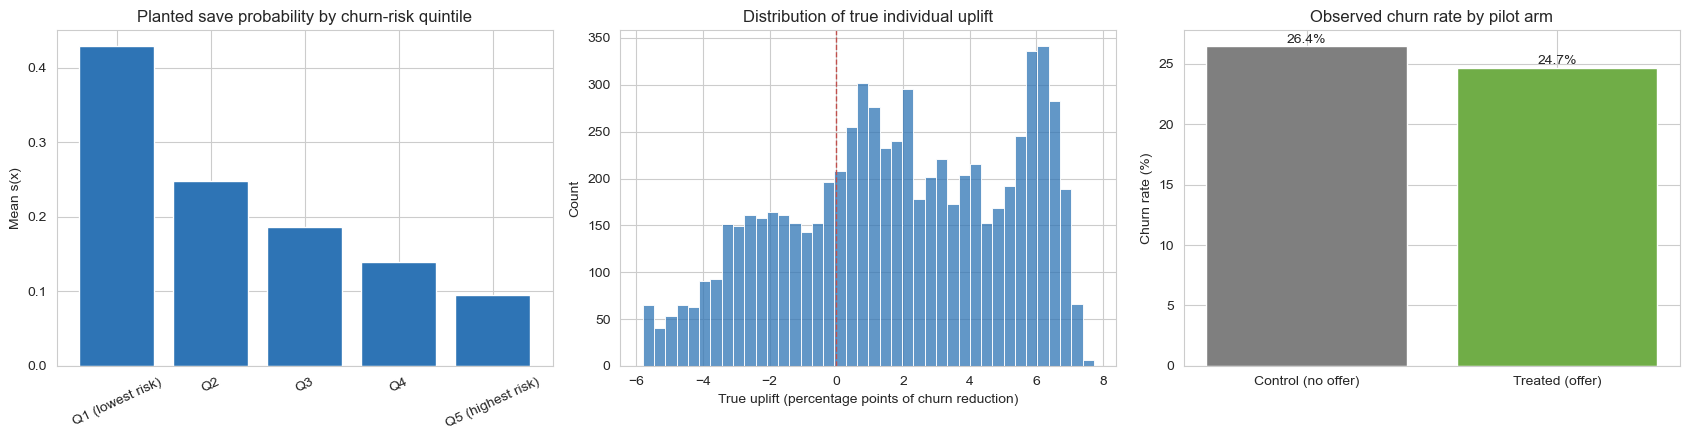

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

risk_quintile = pd.qcut(p0, 5, labels=["Q1 (lowest risk)", "Q2", "Q3", "Q4", "Q5 (highest risk)"])
save_by_risk = pd.Series(save_prob).groupby(risk_quintile, observed=True).mean()
axes[0].bar(save_by_risk.index, save_by_risk.values, color="#2E74B5")
axes[0].set_title("Planted save probability by churn-risk quintile")
axes[0].set_ylabel("Mean s(x)")
axes[0].tick_params(axis="x", rotation=25)

sns.histplot(sim["tau"] * 100, bins=40, color="#2E74B5", ax=axes[1])
axes[1].axvline(0, color="#C0504D", linestyle="--", linewidth=1)
axes[1].set_title("Distribution of true individual uplift")
axes[1].set_xlabel("True uplift (percentage points of churn reduction)")

observed_by_arm = pd.DataFrame({"W": sim["W"], "Y": sim["Y"]}).groupby("W")["Y"].mean() * 100
axes[2].bar(["Control (no offer)", "Treated (offer)"], observed_by_arm.values, color=["#7F7F7F", "#70AD47"])
axes[2].set_title("Observed churn rate by pilot arm")
axes[2].set_ylabel("Churn rate (%)")
for i, v in enumerate(observed_by_arm.values):
    axes[2].text(i, v + 0.3, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.show()


The synthetic uplift analysis demonstrates that the simulated probability of saving a customer decreases across churn-risk quintiles, from approximately 43% in Q1 (lowest risk) to 9% in Q5 (highest risk), highlighting that customers most likely to churn are not necessarily the easiest to retain. The distribution of true individual uplift shows heterogeneous treatment effects, with both positive and negative values, indicating that the simulated offer may reduce churn for some customers but have little or potentially adverse effects for others. The observed churn rate was 26.4% in the control group compared with 24.7% in the treated group, an absolute reduction of 1.7 percentage points (approximately 6.4% relative reduction). These findings illustrate the potential value of targeting customers based on their responsiveness to retention interventions rather than churn risk alone. However, because treatment assignment and individual uplift are simulated, the results demonstrate the methodology rather than establish real-world causal effects.

## 4. Uplift Learners and Hold-Out Evaluation

### 4.1 Features and learners

The uplift models use the same 20 features as Module 3 (the treatment flag is never a feature). Three candidate learners are compared:

- **T-learner (XGBoost):** fits one outcome model on treated customers and one on controls; uplift is the difference in predicted retention. Simple, but each model sees only half the pilot, so it is high-variance.
- **X-learner (XGBoost second stage):** uses each arm's model to impute the *other* arm's counterfactual outcome, then fits a second-stage model on those imputed individual effects (Künzel et al., 2019).
- **X-learner (Ridge second stage):** identical first stage, but a regularized linear second stage. The effect surface is usually smoother than the outcome surface, so a low-variance second stage is a principled choice at small sample sizes.

Two churn-risk baselines are compared against them. **Churn-risk targeting (historical model)** is the realistic baseline: a churn classifier trained on an *independent historical cohort* with the same covariates, which is exactly what Module 3 provides. **Churn-risk targeting (oracle `p0`)** uses the true baseline risk and shows the ceiling for that strategy.


In [6]:
numeric_features = ["tenure", "MonthlyCharges", "services_count", "contract_risk_flag"]
categorical_features = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]
feature_cols = numeric_features + categorical_features
X_all = df[feature_cols]

def encode_features(X_train, X_test):
    """Fit the preprocessor on the training rows only, then transform both sets."""
    pre = ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical_features),
    ])
    A, B = pre.fit_transform(X_train), pre.transform(X_test)
    to_dense = lambda M: M.toarray() if hasattr(M, "toarray") else np.asarray(M)
    return to_dense(A), to_dense(B)

def make_clf(seed=RANDOM_SEED):
    return XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.04, subsample=0.8,
                         colsample_bytree=0.8, min_child_weight=5, reg_lambda=5.0,
                         random_state=seed, n_jobs=1, eval_metric="logloss")

def make_reg(seed=RANDOM_SEED):
    return XGBRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, min_child_weight=10, reg_lambda=10.0,
                        random_state=seed, n_jobs=1)

LEARNERS = ["T-learner (XGBoost)", "X-learner (XGBoost)", "X-learner (Ridge stage 2)"]

def fit_learners(X_tr, w_tr, r_tr, X_te, propensity_fn=None):
    """Fit all three uplift learners. r is RETENTION (1 - churn), so uplift = churn reduction.
    Returns (dict of uplift scores on X_te, estimated no-offer churn risk on X_te)."""
    m1 = make_clf().fit(X_tr[w_tr == 1], r_tr[w_tr == 1])    # retention model, treated
    m0 = make_clf().fit(X_tr[w_tr == 0], r_tr[w_tr == 0])    # retention model, control
    mu1_te, mu0_te = m1.predict_proba(X_te)[:, 1], m0.predict_proba(X_te)[:, 1]

    X1, X0 = X_tr[w_tr == 1], X_tr[w_tr == 0]
    d1 = r_tr[w_tr == 1] - m0.predict_proba(X1)[:, 1]        # imputed effect for treated customers
    d0 = m1.predict_proba(X0)[:, 1] - r_tr[w_tr == 0]        # imputed effect for control customers
    g = 0.5 if propensity_fn is None else propensity_fn(X_te)

    scores = {"T-learner (XGBoost)": mu1_te - mu0_te}
    t1, t0 = make_reg().fit(X1, d1), make_reg().fit(X0, d0)
    scores["X-learner (XGBoost)"] = g * t0.predict(X_te) + (1 - g) * t1.predict(X_te)
    alphas = np.logspace(-1, 4, 20)
    t1r, t0r = RidgeCV(alphas=alphas).fit(X1, d1), RidgeCV(alphas=alphas).fit(X0, d0)
    scores["X-learner (Ridge stage 2)"] = g * t0r.predict(X_te) + (1 - g) * t1r.predict(X_te)
    return scores, 1 - mu0_te

def evaluate_rankings(scores, r, w, tau_true, k=0.2):
    """Observed metrics (Qini, uplift@k) plus ground-truth metrics available only in simulation."""
    rows = {}
    m = len(r)
    for name, sc in scores.items():
        top = np.argsort(-sc)[: int(k * m)]
        rows[name] = {
            "Qini AUC": qini_auc_score(r, sc, w),
            "Observed uplift@20%": uplift_at_k(r, sc, w, strategy="overall", k=k),
            "Rank corr. with true uplift": spearmanr(sc, tau_true).correlation,
            "True net saves @20% budget (% of customers)": 100 * tau_true[top].sum() / m,
        }
    return pd.DataFrame(rows).T

RISK_HIST = "Churn-risk targeting (historical model)"
RISK_ORACLE = "Churn-risk targeting (oracle p0)"
ORACLE_UPLIFT = "Oracle uplift ranking"

def run_replicate(divergence, seed, rows=None, assign_prob=0.5, estimate_propensity=False):
    """One full simulate -> split -> fit -> evaluate cycle. Returns tables and scores."""
    idx = np.arange(n) if rows is None else rows
    ap = assign_prob if np.isscalar(assign_prob) else assign_prob[idx]
    s_all = make_save_prob(divergence)
    sm = simulate_outcomes(p0[idx], s_all[idx], backfire_prob[idx], seed, ap)
    r = 1 - sm["Y"]
    tr, te = train_test_split(np.arange(len(idx)), test_size=0.2,
                              stratify=sm["W"] * 2 + sm["Y"], random_state=seed)
    X_tr, X_te = encode_features(X_all.iloc[idx[tr]], X_all.iloc[idx[te]])

    prop_fn = None
    if estimate_propensity:
        lr = LogisticRegression(max_iter=2000).fit(X_tr, sm["W"][tr])
        prop_fn = lambda Xq: np.clip(lr.predict_proba(Xq)[:, 1], 0.05, 0.95)

    uplifts, _ = fit_learners(X_tr, sm["W"][tr], r[tr], X_te, prop_fn)
    risk_hist = make_clf().fit(X_tr, sm["Y_hist"][tr]).predict_proba(X_te)[:, 1]
    scores = {**uplifts, RISK_HIST: risk_hist, RISK_ORACLE: p0[idx][te], ORACLE_UPLIFT: sm["tau"][te]}
    table = evaluate_rankings(scores, r[te], sm["W"][te], sm["tau"][te])
    return dict(table=table, scores=scores, r_te=r[te], w_te=sm["W"][te], tau_te=sm["tau"][te])


### 4.2 Hold-out results for the primary pilot

Qini curves show how many additional customers are retained as the campaign extends down a ranked list. A curve that bows well above the diagonal (random targeting) means the ranking concentrates the offer's benefit near the top. The **Oracle uplift ranking** is the best any ranking could do.


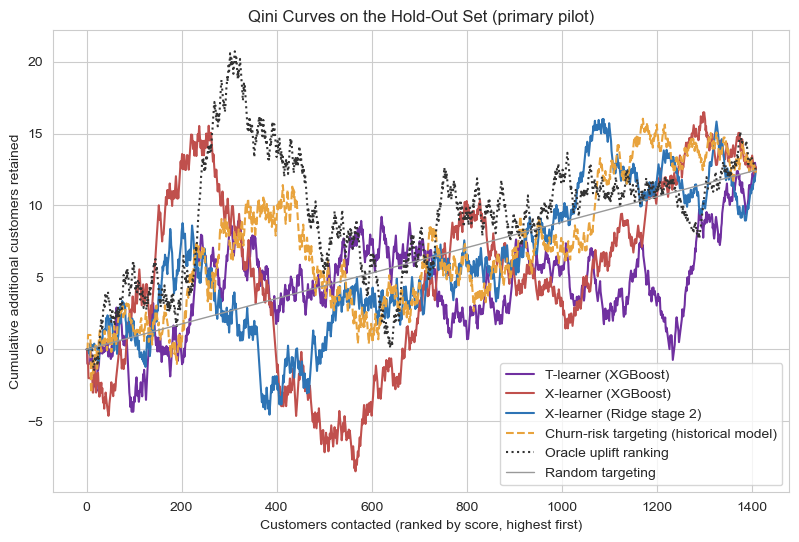

,Qini AUC,Observed uplift@20%,Rank corr. with true uplift,True net saves @20% budget (% of customers)
T-learner (XGBoost),-0.0053,0.0294,0.5058,0.9251
X-learner (XGBoost),-0.0031,0.0744,0.6967,0.9635
X-learner (Ridge stage 2),-0.0012,0.0209,0.8900,1.0864
Churn-risk targeting (historical model),0.0028,0.0622,0.9375,1.1337
Churn-risk targeting (oracle p0),0.0088,0.0771,0.9311,1.0978
Oracle uplift ranking,0.0096,0.1352,1.0000,1.2401


In [7]:
main = run_replicate(PRIMARY_DIVERGENCE, RANDOM_SEED)

fig, ax = plt.subplots(figsize=(9.5, 6))
styles = {
    "T-learner (XGBoost)": ("#7030A0", "-"),
    "X-learner (XGBoost)": ("#C0504D", "-"),
    "X-learner (Ridge stage 2)": ("#2E74B5", "-"),
    RISK_HIST: ("#E8A33D", "--"),
    ORACLE_UPLIFT: ("#333333", ":"),
}
for name, (color, ls) in styles.items():
    x, y = qini_curve(main["r_te"], main["scores"][name], main["w_te"])
    ax.plot(x, y, color=color, linestyle=ls, label=name)
ax.plot([0, x[-1]], [0, y[-1]], color="#999999", linewidth=1, label="Random targeting")
ax.set_xlabel("Customers contacted (ranked by score, highest first)")
ax.set_ylabel("Cumulative additional customers retained")
ax.set_title("Qini Curves on the Hold-Out Set (primary pilot)")
ax.legend()
plt.show()

main["table"].round(4)


The Qini curves compare the cumulative retention gains achieved by different uplift models on the hold-out set, ranking customers from highest to lowest predicted treatment effect. The T-learner (XGBoost), X-learners (XGBoost and Ridge), and historical churn-risk targeting model show fluctuating performance as more customers are contacted, with no single learned model consistently outperforming the others across the entire ranking. The oracle uplift ranking provides an idealized benchmark based on true simulated individual uplift, while random targeting represents the baseline. Although several models achieve positive cumulative gains in parts of the curve, their instability suggests that customer prioritization remains sensitive to the ranking method and the number of customers targeted. Since treatment assignment and true individual uplift are simulated, these results demonstrate the potential and limitations of uplift-based targeting rather than validated real-world retention effectiveness.

## 5. Repeated Simulation and Learner Selection

One simulated pilot is one random draw. To avoid reading too much into it, the full experiment is repeated across 20 independent pilots (new assignment and outcome draws each time, with the planted structure unchanged).

**Selection rule (uses only quantities a real team would also have).** Learners are compared on **Qini AUC across the repeated pilots**. Taking the plain maximum is fragile when the gaps between learners are smaller than the noise, so the **one-standard-error rule** is used instead: among all learners whose mean Qini AUC is within one paired standard error of the best, choose the *simplest*. Complexity is ranked a priori as: ridge second stage < XGBoost second stage < T-learner (two separately fit flexible models). The preference for a low-variance second stage was stated in Section 4.1, before any results were examined.


In [8]:
N_SEEDS_SELECTION = 20
selection_runs = pd.concat(
    [run_replicate(PRIMARY_DIVERGENCE, seed)["table"].assign(seed=seed) for seed in range(N_SEEDS_SELECTION)]
)

g = selection_runs.groupby(level=0)
summary = pd.concat(
    {"mean": g.mean(numeric_only=True).drop(columns="seed"),
     "std": g.std(numeric_only=True).drop(columns="seed")}, axis=1
).round(4)
order = LEARNERS + [RISK_HIST, RISK_ORACLE, ORACLE_UPLIFT]
summary.loc[order]


mean                      \
                                        Qini AUC Observed uplift@20%   
T-learner (XGBoost)                       0.0145              0.0615   
X-learner (XGBoost)                       0.0139              0.0520   
X-learner (Ridge stage 2)                 0.0110              0.0366   
Churn-risk targeting (historical model)   0.0147              0.0363   
Churn-risk targeting (oracle p0)          0.0143              0.0475   
Oracle uplift ranking                     0.0173              0.0598   

                                                                     \
                                        Rank corr. with true uplift   
T-learner (XGBoost)                                          0.4022   
X-learner (XGBoost)                                          0.5685   
X-learner (Ridge stage 2)                                    0.7537   
Churn-risk targeting (historical model)                      0.9210   
Churn-risk targeting (oracle p0)                             0.9364   
Oracle uplift ranking                                        1.0000   

                                                                                     \
                                        True net saves @20% budget (% of customers)   
T-learner (XGBoost)                                                          0.8932   
X-learner (XGBoost)                                                          0.8886   
X-learner (Ridge stage 2)                                                    0.9853   
Churn-risk targeting (historical model)                                      1.1214   
Churn-risk targeting (oracle p0)                                             1.1305   
Oracle uplift ranking                                                        1.2467   

                                             std                      \
                                        Qini AUC Observed uplift@20%   
T-learner (XGBoost)                       0.0179              0.0765   
X-learner (XGBoost)                       0.0163              0.0610   
X-learner (Ridge stage 2)                 0.0153              0.0513   
Churn-risk targeting (historical model)   0.0173              0.0610   
Churn-risk targeting (oracle p0)          0.0161              0.0650   
Oracle uplift ranking                     0.0166              0.0586   

                                                                     \
                                        Rank corr. with true uplift   
T-learner (XGBoost)                                          0.0987   
X-learner (XGBoost)                                          0.1147   
X-learner (Ridge stage 2)                                    0.1231   
Churn-risk targeting (historical model)                      0.0088   
Churn-risk targeting (oracle p0)                             0.0036   
Oracle uplift ranking                                        0.0000   

                                                                                     
                                        True net saves @20% budget (% of customers)  
T-learner (XGBoost)                                                          0.0595  
X-learner (XGBoost)                                                          0.0908  
X-learner (Ridge stage 2)                                                    0.1266  
Churn-risk targeting (historical model)                                      0.0128  
Churn-risk targeting (oracle p0)                                             0.0091  
Oracle uplift ranking                                                        0.0066

In [9]:
# Paired comparison against the realistic risk-targeting baseline, seed by seed
net_col = "True net saves @20% budget (% of customers)"
pivot = selection_runs.reset_index().pivot(index="seed", columns="index", values=net_col)

paired = pd.DataFrame({
    "Mean difference vs. risk targeting (pp of customers)": [(pivot[m] - pivot[RISK_HIST]).mean() for m in LEARNERS],
    "Share of pilots where learner beats risk targeting": [(pivot[m] > pivot[RISK_HIST]).mean() for m in LEARNERS],
}, index=LEARNERS).round(3)
paired


,Mean difference vs. risk targeting (pp of customers),Share of pilots where learner beats risk targeting
T-learner (XGBoost),-0.228,0.00
X-learner (XGBoost),-0.233,0.00
X-learner (Ridge stage 2),-0.136,0.15


In [10]:
q = selection_runs.reset_index().pivot(index="seed", columns="index", values="Qini AUC")
mean_q = q[LEARNERS].mean()
best_by_mean = mean_q.idxmax()
COMPLEXITY_ORDER = ["X-learner (Ridge stage 2)", "X-learner (XGBoost)", "T-learner (XGBoost)"]   # simplest first

rows = []
for m in LEARNERS:
    gap = mean_q[best_by_mean] - mean_q[m]
    se = (q[best_by_mean] - q[m]).std(ddof=1) / np.sqrt(len(q)) if m != best_by_mean else 0.0
    rows.append({"learner": m, "mean Qini AUC": mean_q[m], "gap to best": gap,
                 "paired SE of gap": se, "within 1 SE of best": bool(m == best_by_mean or gap <= se)})
selection_table = pd.DataFrame(rows).set_index("learner")

PRIMARY_LEARNER = next(m for m in COMPLEXITY_ORDER if selection_table.loc[m, "within 1 SE of best"])
print(f"Highest mean Qini AUC (plain argmax): {best_by_mean}")
print(f"Selected by one-standard-error rule:   {PRIMARY_LEARNER}")
selection_table.round(4)


Highest mean Qini AUC (plain argmax): T-learner (XGBoost)
Selected by one-standard-error rule:   X-learner (XGBoost)


,mean Qini AUC,gap to best,paired SE of gap,within 1 SE of best
learner,,,,
T-learner (XGBoost),0.0145,0.0000,0.0000,True
X-learner (XGBoost),0.0139,0.0006,0.0021,True
X-learner (Ridge stage 2),0.0110,0.0035,0.0031,False


In [11]:
# Informational only: ground truth is NOT available in real use and is NOT used to select anything.
gt = selection_runs.groupby(level=0)[[net_col, "Rank corr. with true uplift"]].mean().loc[LEARNERS]
print("Ground-truth view of the same three learners (simulation only):")
print(gt.round(3).to_string())
print(f"\nSelected learner has the best true net saves of the three: {gt[net_col].idxmax() == PRIMARY_LEARNER}")


Ground-truth view of the same three learners (simulation only):
                           True net saves @20% budget (% of customers)  Rank corr. with true uplift
T-learner (XGBoost)                                              0.893                        0.402
X-learner (XGBoost)                                              0.889                        0.568
X-learner (Ridge stage 2)                                        0.985                        0.754

Selected learner has the best true net saves of the three: False


**On the selection.** The plain maximum of mean Qini AUC and the one-standard-error rule can disagree, and the table above shows why the rule exists: the gap between the top learners is smaller than its own standard error, so the observable metric cannot separate them and the plain argmax would effectively be a coin flip. The one-standard-error rule resolves that tie toward the simpler, lower-variance learner using only information a real team would have. The ground-truth cell is shown purely for transparency and is **not** used to choose anything. (In real use that ground truth does not exist, which is exactly why a principled rule is needed.)

**How to read the paired table.** A negative mean difference and a low win-rate mean the uplift learner is, on average, *worse* than simply ranking customers by churn risk at this pilot size and divergence. That is a legitimate and common outcome: at roughly 7,000 customers and a ~27% base churn rate, estimating *individual* treatment effects (a difference between two noisy binary outcomes) is much harder than estimating churn risk itself. The next two sections ask when, and with how much data, this changes.


## 6. When Does Uplift Targeting Beat Churn-Risk Targeting?

Uplift targeting can only help when *who responds to an offer* differs from *who is likely to leave*. If persuadability simply rises with risk, then ranking by risk is already nearly optimal. This section sweeps the divergence dial `κ` from "persuadability rises with risk" (negative) to "highest-risk customers are committed leavers" (large positive), holding the average save rate fixed at 22%, and compares:

- **Potential:** how much better the *oracle* uplift ranking is than risk targeting (the headroom that exists)
- **Realized:** how much of it the fitted learner actually captures at this pilot size


In [12]:
KAPPAS = [-0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
N_SEEDS_SWEEP = 10
sweep_rows = []

for kappa in KAPPAS:
    runs = pd.concat([run_replicate(kappa, seed)["table"].assign(seed=seed) for seed in range(N_SEEDS_SWEEP)])
    means = runs.groupby(level=0)[net_col].mean()
    tau_k = p0 * make_save_prob(kappa) - (1 - p0) * backfire_prob
    sweep_rows.append({
        "divergence κ": kappa,
        "rank corr(risk, true uplift)": spearmanr(p0, tau_k).correlation,
        "risk targeting": means[RISK_HIST],
        "oracle uplift": means[ORACLE_UPLIFT],
        "fitted learner": means[PRIMARY_LEARNER],
    })

sweep = pd.DataFrame(sweep_rows).set_index("divergence κ")
sweep["oracle gain vs. risk (%)"] = 100 * (sweep["oracle uplift"] / sweep["risk targeting"] - 1)
sweep["learner gain vs. risk (%)"] = 100 * (sweep["fitted learner"] / sweep["risk targeting"] - 1)
sweep.round(3)


,"rank corr(risk, true uplift)",risk targeting,oracle uplift,fitted learner,oracle gain vs. risk (%),learner gain vs. risk (%)
divergence κ,,,,,,
-0.5,0.984,5.220,5.403,5.019,3.496,-3.866
0.0,0.982,3.617,3.769,3.316,4.186,-8.320
0.5,0.973,2.168,2.288,1.795,5.570,-17.201
1.0,0.935,1.121,1.247,0.865,11.235,-22.849
1.5,0.851,0.525,0.674,0.432,28.450,-17.664
2.0,0.719,0.230,0.368,0.209,59.886,-9.235


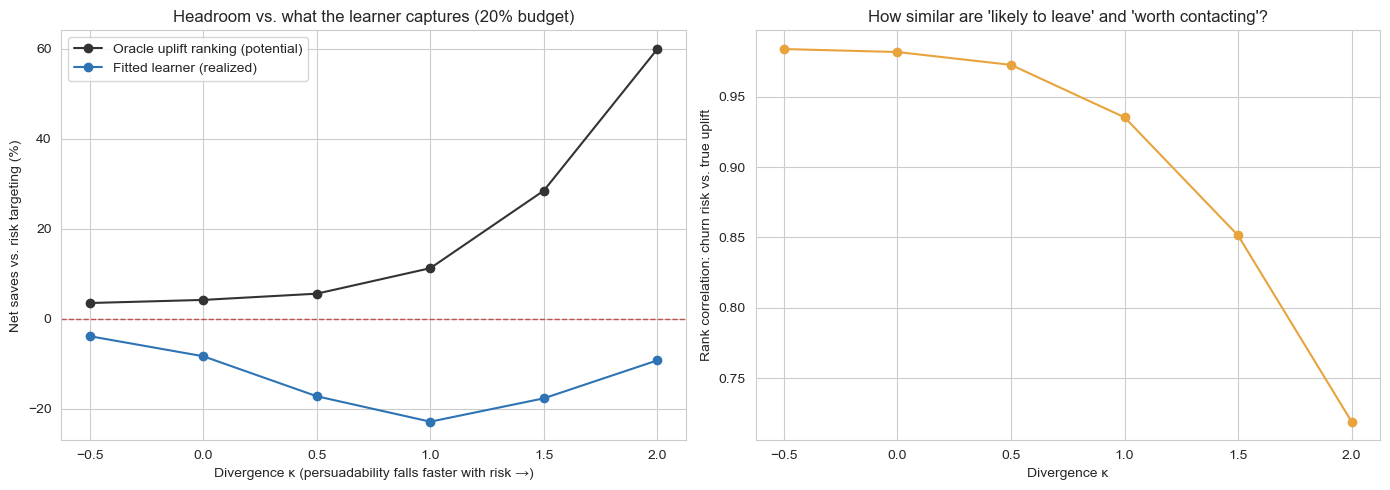

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(sweep.index, sweep["oracle gain vs. risk (%)"], marker="o", color="#333333", label="Oracle uplift ranking (potential)")
axes[0].plot(sweep.index, sweep["learner gain vs. risk (%)"], marker="o", color="#2E74B5", label=f"Fitted learner (realized)")
axes[0].axhline(0, color="#C0504D", linestyle="--", linewidth=1)
axes[0].set_xlabel("Divergence κ (persuadability falls faster with risk →)")
axes[0].set_ylabel("Net saves vs. risk targeting (%)")
axes[0].set_title("Headroom vs. what the learner captures (20% budget)")
axes[0].legend()

axes[1].plot(sweep.index, sweep["rank corr(risk, true uplift)"], marker="o", color="#E8A33D")
axes[1].set_xlabel("Divergence κ")
axes[1].set_ylabel("Rank correlation: churn risk vs. true uplift")
axes[1].set_title("How similar are 'likely to leave' and 'worth contacting'?")

plt.tight_layout()
plt.show()


**Two separate things are visible here and should not be conflated.** The *potential* line shows whether uplift ranking *could* beat risk targeting in a world with that much divergence. The *realized* line shows whether a learner fit on a pilot of this size actually captures it.

In the executed run, the oracle ranking's headroom over risk targeting grows steadily as divergence rises, from a few percent when persuadability rises with risk to roughly 60% when the highest-risk customers are committed leavers. The fitted learner, however, stays *below* risk targeting at every divergence level tested (all comparisons here use a 20% campaign budget). So the opportunity is real in strongly divergent worlds, but a pilot of this size cannot find it. Whether SmartTel's customers resemble a high-divergence world is exactly what a real pilot would reveal, and nothing in this simulation can say. The next section asks how much data it would take.
